# 3.4 Comparação dos domínios

Os notebooks 2 e 3 analisam as mesmas 2.370 janelas. Aqui comparamos o que cada domínio mostra.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import seaborn as sns
from scipy.stats import mannwhitneyu

from src.freq_features import FS, espectro
from src.io_utils import DATA_DIR
from src.windowing import get_matriz_acc

tempo = pd.read_csv("../data/processed/features_tempo.csv")
frequencia = pd.read_csv("../data/processed/features_freq.csv")
janelas = pd.read_csv("../data/processed/janelas.csv")

# Confere se as tabelas têm as mesmas janelas na mesma ordem.
identificacao = ["arquivo", "id", "rotulo", "F", "SV", "SP", "C", "jan"]
assert tempo[identificacao].equals(frequencia[identificacao])

colunas_tempo = tempo.columns.drop(identificacao).tolist()
colunas_freq = frequencia.columns.drop(identificacao).tolist()
colunas = colunas_tempo + colunas_freq
dados = pd.concat([tempo, frequencia[colunas_freq]], axis=1)

## 1. Tempo e frequência no mesmo trecho

Usamos os pares do notebook 3, gravados na mesma data. Em cima, os primeiros 0,2 s da janela. Embaixo, o espectro de 20 a 22 s. `f1` é a frequência de maior magnitude entre 30 e 200 Hz.

 SP   Condição    RMS  f1 (Hz)
  1   saudável 0.0412     56.5
  1 defeituosa 0.0328     52.0
  2   saudável 0.0998     99.0
  2 defeituosa 0.1083     92.5
  3   saudável 0.2877    133.5
  3 defeituosa 0.4776    127.5


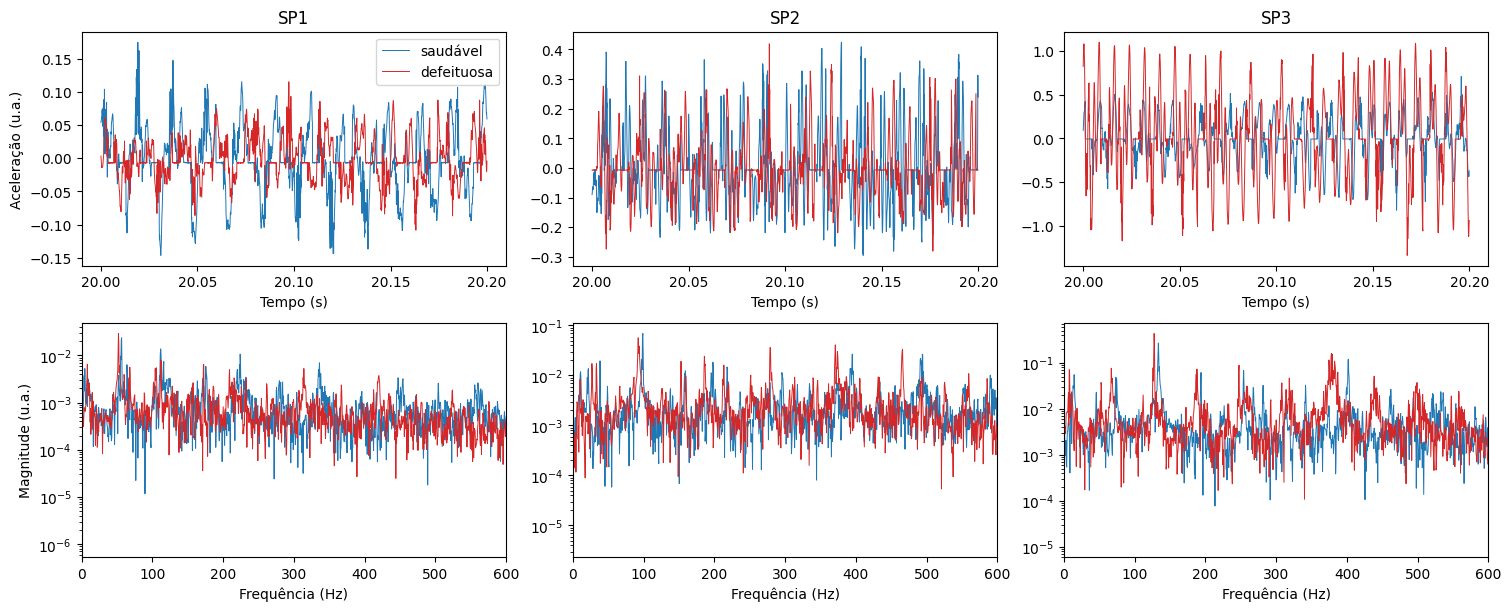

In [2]:
rotulos = {"saudavel": "saudável", "defeituoso": "defeituosa"}
cores = {"saudavel": "tab:blue", "defeituoso": "tab:red"}
janela = 10  # 20 a 22 s
instantes = 20 + np.arange(2000) / FS

fig, paineis = plt.subplots(2, 3, figsize=(15, 6), layout="constrained")
linhas = []

for sp, (ax_tempo, ax_freq) in enumerate(paineis.T, start=1):
    arquivos = {
        "saudavel": f"F0_SV0_SP{sp}_C1_R1.mat",
        "defeituoso": f"F1_SV3_SP{sp}_C1.mat",
    }
    for condicao, arquivo in arquivos.items():
        sinal = get_matriz_acc(arquivo, janelas)[janela]
        f, magnitude = espectro(sinal, FS)
        magnitude = magnitude[0]

        cor = cores[condicao]
        ax_tempo.plot(instantes, sinal[:2000], color=cor, lw=0.7, label=rotulos[condicao])
        ax_freq.semilogy(f, magnitude, color=cor, lw=0.7)

        faixa = (f >= 30) & (f <= 200)
        f1 = f[faixa][magnitude[faixa].argmax()]
        mesmo_trecho = (dados["arquivo"] == arquivo) & (dados["jan"] == janela)
        rms = dados.loc[mesmo_trecho, "rms"].iloc[0]
        linhas.append({"SP": sp, "Condição": rotulos[condicao], "RMS": rms, "f1 (Hz)": f1})

    ax_tempo.set(title=f"SP{sp}", xlabel="Tempo (s)")
    ax_tempo.set_xticks([20, 20.05, 20.10, 20.15, 20.20])
    ax_freq.set(xlabel="Frequência (Hz)", xlim=(0, 600))

paineis[0, 0].set_ylabel("Aceleração (u.a.)")
paineis[1, 0].set_ylabel("Magnitude (u.a.)")
paineis[0, 0].legend()
print(pd.DataFrame(linhas).round(4).to_string(index=False))
plt.savefig("../results/figures/comparacao_tempo_frequencia.png", dpi=150)
plt.show()

- **Tempo.** Neste exemplo, o RMS é menor na defeituosa em SP1, próximo em SP2 e maior em SP3.
- **Frequência.** Nos três pares, a defeituosa tem `f1` menor. O espectro mostra em quais frequências a vibração se concentra.

### Potência nas bandas

Somamos a potência das quatro bandas e comparamos com três vezes a variância do sinal. O fator 3 vem da normalização da FFT com Hann. A relação é aproximada.

0.05    0.817
0.50    0.994
0.95    1.177


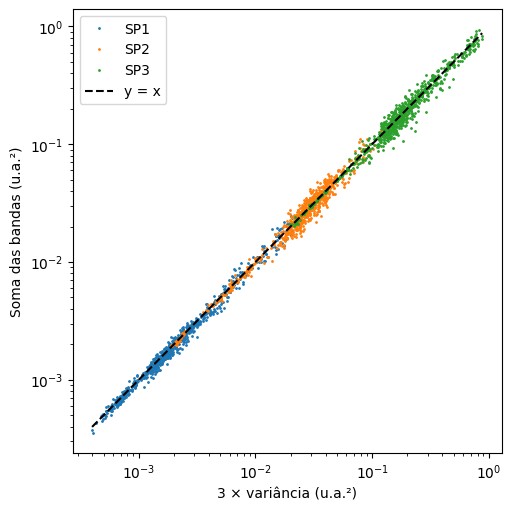

In [3]:
bandas = [coluna for coluna in colunas_freq if coluna.startswith("pot_")]
soma_bandas = dados[bandas].sum(axis=1)
tres_variancias = 3 * dados["desvio"] ** 2
razao = soma_bandas / tres_variancias
print(razao.quantile([0.05, 0.5, 0.95]).round(3).to_string())

fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")
for sp, grupo in dados.groupby("SP"):
    indices = grupo.index
    ax.loglog(tres_variancias[indices], soma_bandas[indices], ".", ms=2, label=f"SP{sp}")

limites = [tres_variancias.min(), tres_variancias.max()]
ax.plot(limites, limites, "k--", label="y = x")
ax.set(xlabel="3 × variância (u.a.²)", ylabel="Soma das bandas (u.a.²)")
ax.legend()
plt.savefig("../results/figures/rms_vs_potencia_espectral.png", dpi=150)
plt.show()

A razão tem mediana de 0,994. A soma das bandas acompanha a variância. Separar por bandas mostra onde a potência está concentrada.

## 2. Quais medidas separam as condições?

Usamos a mediana de cada registro. A AUC compara a ordem dos valores nas duas condições. Perto de 0,5, elas se misturam. Perto de 0 ou 1, elas se separam.

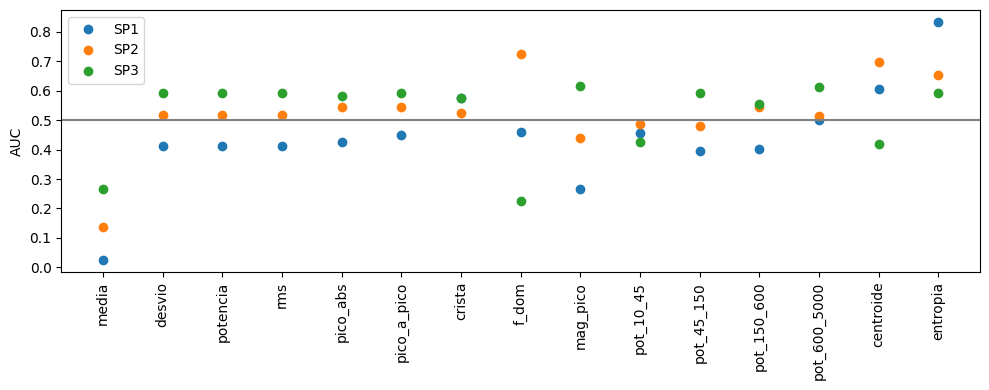

In [4]:
registros = dados.groupby(["arquivo", "SP", "rotulo"], as_index=False)[colunas].median()

tab_auc = pd.DataFrame(index=colunas)
for sp, grupo in registros.groupby("SP"):
    saudaveis = grupo[grupo["rotulo"] == "saudavel"]
    defeituosas = grupo[grupo["rotulo"] == "defeituoso"]

    # Calcula a AUC de uma característica por vez.
    valores = []
    for coluna in colunas:
        u = mannwhitneyu(defeituosas[coluna], saudaveis[coluna]).statistic
        valores.append(u / (len(defeituosas) * len(saudaveis)))
    tab_auc[f"SP{sp}"] = valores

ax = tab_auc.plot(marker="o", linestyle="none", rot=90, figsize=(10, 4))
ax.axhline(0.5, color="gray")
ax.set_xticks(range(len(colunas)), colunas)
ax.set_ylabel("AUC")
plt.tight_layout()
plt.savefig("../results/figures/auc_caracteristicas.png", dpi=150)
plt.show()

O RMS muda de sentido entre os níveis de operação e o fator de crista separa pouco. A entropia é maior nas defeituosas nos três níveis (AUC de 0,83, 0,65 e 0,59). A diferença diminui de SP1 a SP3.

## 3. Redundância e escolha das características

A correlação mostra quais medidas variam juntas. A segunda matriz compara os valores após padronizar cada medida dentro do seu `SP`.

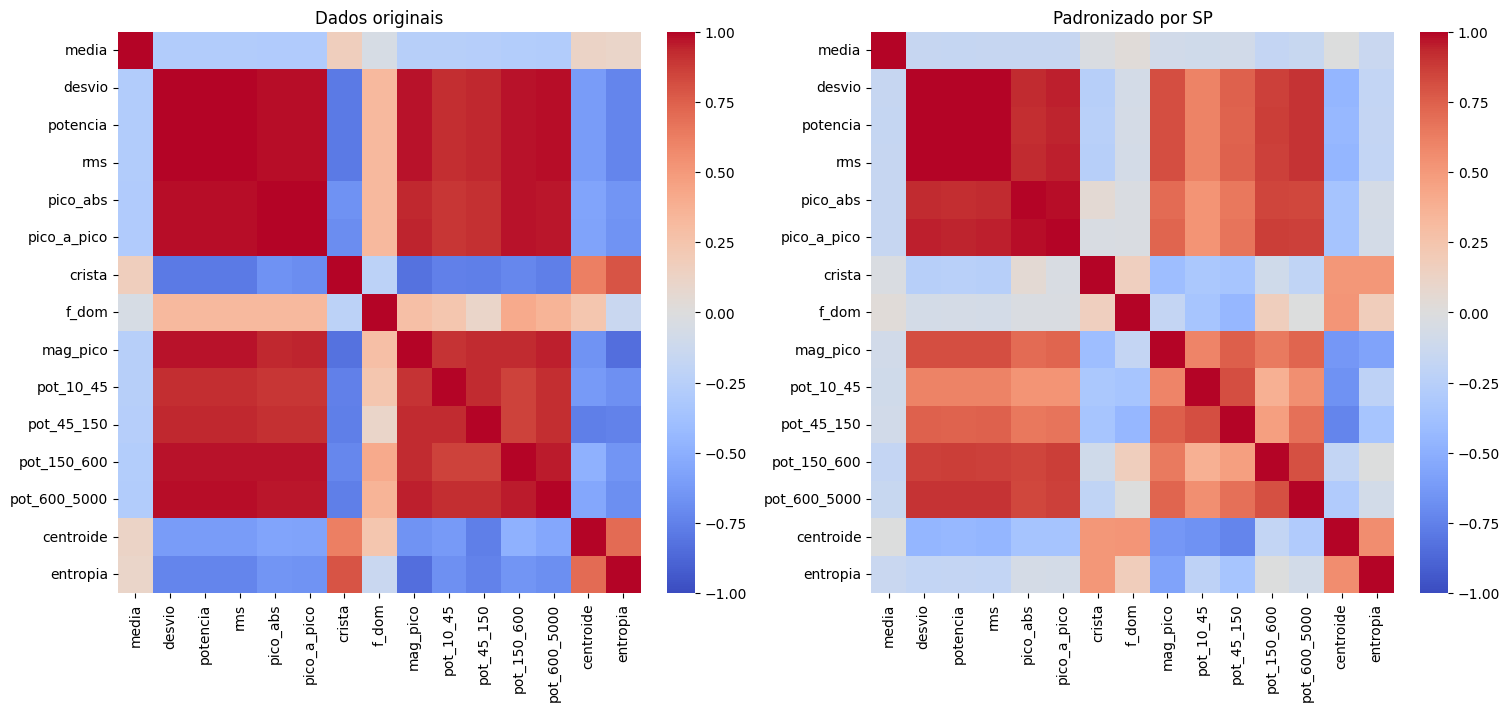

In [5]:
# Centraliza e põe os valores na mesma escala dentro de cada SP.
por_sp = dados.groupby("SP")[colunas]
padronizadas = (dados[colunas] - por_sp.transform("mean")) / por_sp.transform("std")

fig, paineis = plt.subplots(1, 2, figsize=(15, 7), layout="constrained")
for ax, valores, titulo in zip(paineis, [dados[colunas], padronizadas],
                              ["Dados originais", "Padronizado por SP"]):
    matriz = valores.corr(method="spearman")
    sns.heatmap(matriz, vmin=-1, vmax=1, cmap="coolwarm", ax=ax)
    ax.set_title(titulo)

plt.savefig("../results/figures/correlacao_caracteristicas.png", dpi=150)
plt.show()

- **A (tempo)** usa RMS e fator de crista. Potência, desvio e picos se correlacionam com o RMS (ρ ≥ 0,92 após padronizar por `SP`). A média fica de fora porque varia com a data de gravação.
- **B (frequência)** usa as oito medidas espectrais. Entre elas, todas as correlações têm módulo abaixo de 0,90 após padronizar por `SP`.
- **C (combinado)** reúne A e B.

Na classificação, a seleção será conferida apenas nos dados de treino.

## 4. Data de gravação

Os defeituosos foram todos gravados em setembro. Dos saudáveis, só o `R1` de cada grupo é de setembro, e o `R2` e o `R3` são de novembro (`AccData.DATE`). Se uma característica muda com a data, uma diferença entre as condições pode ser, em parte, uma diferença entre sessões de gravação. Aqui isso é verificado na média do sinal, por registro.

rotulo    defeituoso  saudavel
mes                           
novembro           0        12
setembro          81         6


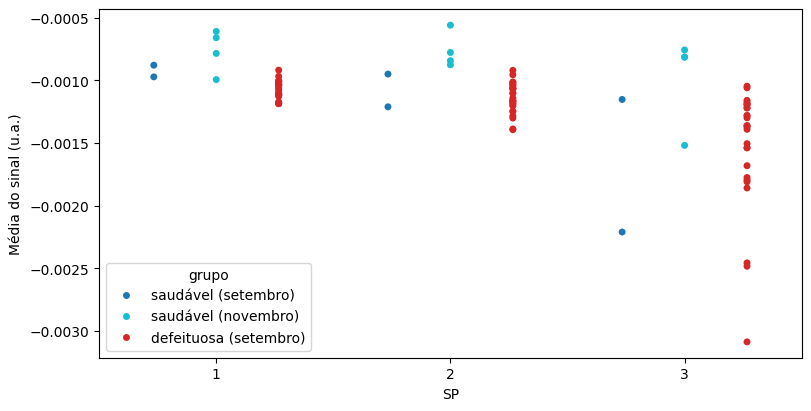

In [6]:
datas = []
for arquivo in registros["arquivo"]:
    mat = sio.loadmat(DATA_DIR / arquivo, simplify_cells=True, variable_names=["AccData"])
    datas.append(mat["AccData"]["DATE"])

registros["mes"] = pd.to_datetime(datas, format="%d-%b-%Y").month
registros["mes"] = registros["mes"].map({9: "setembro", 11: "novembro"})
registros["grupo"] = registros["rotulo"].map(rotulos) + " (" + registros["mes"] + ")"
print(pd.crosstab(registros["mes"], registros["rotulo"]).to_string())

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
sns.stripplot(data=registros, x="SP", y="media", hue="grupo", dodge=True,
              jitter=False, palette=["tab:blue", "tab:cyan", "tab:red"], ax=ax)
ax.set_ylabel("Média do sinal (u.a.)")
plt.savefig("../results/figures/caracteristicas_por_data.png", dpi=150)
plt.show()

**O que se vê.**

- **A data se confunde com a condição:** 12 dos 18 saudáveis são de novembro, e nenhum defeituoso é.
- **A média do sinal acompanha a data, não a condição.** Em SP1 e SP2, os saudáveis de novembro têm média mais alta (menos negativa) que os de setembro, e os saudáveis de setembro ficam dentro da faixa dos defeituosos. Se todos os saudáveis fossem comparados com os defeituosos, a média pareceria separar as condições, mas o que ela separa é a sessão de gravação. Em SP3, o padrão não é claro.
- **Consequências:**
  - a média ficou fora dos conjuntos de características (seção 3);
  - nas outras características, a comparação usando só os saudáveis de setembro é o controle mais próximo disponível. A investigação da 3.6 (notebook 6, seção 3) faz esse controle para o pico de base;
  - na classificação (2ª entrega), vale avaliar também só com os registros de setembro.